# Alanine dipeptide: C7eq → C7ax transition paths

100 PathGennie reactive paths, 38 through the α<sub>R</sub> region and 62 through the α<sub>L</sub> region.
FDM is computed from the aligned Cartesian coordinates of all peptide atoms (L² distance, σ = median, α = 0);
no dihedral angles are given to it. The surrogate then asks which backbone torsions explain FDM 0.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # repository root (notebook lives in systems/<name>/)
sys.path[:0] = [str(ROOT), str(Path.cwd())]
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathfdm import embed
from pathfdm.features import feature_matrix
from pathfdm.surrogate import fit_surrogate
from pathfdm.evaluation import auc_per_coordinate, kmeans_ari, align_signs, compare_embeddings
from pathfdm.plotting import apply_style, plot_space, plot_parity, plot_beeswarm
import load_data as D
apply_style()
N_JOBS = 8

## Load the paths

In [2]:
ts, labels = D.load(n_jobs=N_JOBS)
print(dict(zip(*np.unique(labels, return_counts=True))))

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

100 trajectories | 22 solute atoms + 0 water oxygens | 128-574 frames | 66 coordinates per frame
{np.int64(0): np.int64(38), np.int64(1): np.int64(62)}


## FDM embedding

sigma = 5.258 | eigenvalues [0.1689 0.0555 0.0275 0.0255]
AUC (alpha_R vs alpha_L) of FDM 0-3: [1.    0.569 0.555 0.519]
k-means (k = 2) on FDM 0-1: ARI = 1.00


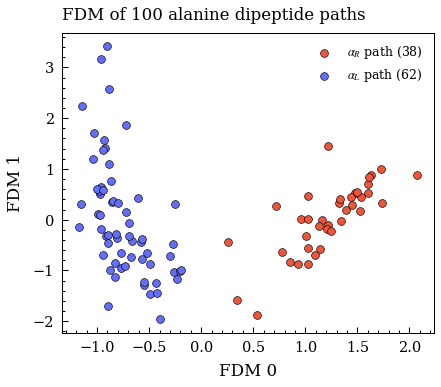

In [3]:
Z, model = embed(ts.fd, metric="l2", sigma="median", alpha=0.0, return_model=True, n_jobs=N_JOBS)
print(f"sigma = {model.sigma_:.3f} | eigenvalues {np.round(model.eigenvals[:4], 4)}")
print("AUC (alpha_R vs alpha_L) of FDM 0-3:", np.round(auc_per_coordinate(Z, labels), 3))
print(f"k-means (k = 2) on FDM 0-1: ARI = {kmeans_ari(Z, labels):.2f}")
plot_space(Z, labels, D.LABEL_CONFIG, title="FDM of 100 alanine dipeptide paths"); plt.show()

## Descriptors and surrogate model

The surrogate is an ExtraTrees regressor (500 trees) predicting FDM 0 from the standardized
descriptors. **Out-of-bag R²**: each trajectory predicted by the trees that did not see it. **Cross-validation**:
5-fold, repeated 5 times; R² is the mean ± sd over the 25 folds, and the parity plot shows the mean of the five
held-out predictions of every trajectory. The beeswarm shows the SHAP value of each descriptor for every
trajectory (colour = descriptor value).

Descriptors: Φ, Ψ, ω<sub>1</sub>, ω<sub>2</sub> and the C7 hydrogen-bond distance, each summarized by
σ, ⟨⟩, Δ and γ<sub>1</sub> (20 descriptors). σ, ⟨⟩ and γ<sub>1</sub> are computed on the raw path and Δ on the
denoised path (`stats_on="mixed"`).

In [4]:
desc = D.descriptors(ts, n_jobs=N_JOBS)
X, names = feature_matrix(desc, D.DESC_NAMES, stats_on="mixed", zero_degenerate_skew=False)
res = fit_surrogate(X, Z[:, 0], names)
print(res.summary())
res.table(8).round(3)

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/core/universe.py:607: DeprecationWarning: Bond guessing through the `guess_bonds` keyword is deprecated and will be removed in MDAnalysis 3.0. Instead, pass 'bonds', 'angles', and 'dihedrals' to the `to_guess` keyword in Universe for guessing these if they are not present, or `force_guess` if they are and you wish to replace these bonds with guessed values. The kwargs `fudge_factor`, `vdwradii`, and `lower_bound` are also deprecated and will be removed in MDAnalysis 3.0, where they should be passed into the Context for guessing on Universe instantiation. If using guess_TopologyAttrs, pass these kwargs to the method instead, as they will override the previous Context values.
  warnings.warn(
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/core/universe.py:607: DeprecationWarning: Bond guessing through the `guess_bonds` keyword is deprecated and will be removed in MDAnalysis 

20 descriptors | out-of-bag R2 = 0.974 | 5-fold CV x 5: R2 = 0.968 +/- 0.018


,feature,shap_share,frac_folds_rank1
0,$\sigma(\phi)$,0.283,0.76
1,$\langle \phi \rangle$,0.259,0.24
2,$\langle \psi \rangle$,0.145,0.00
3,$\gamma_1(\phi)$,0.101,0.00
4,$\langle c7\text{-}h \rangle$,0.047,0.00
5,$\Delta(c7\text{-}h)$,0.046,0.00
6,$\gamma_1(\psi)$,0.033,0.00
7,$\Delta(\psi)$,0.021,0.00


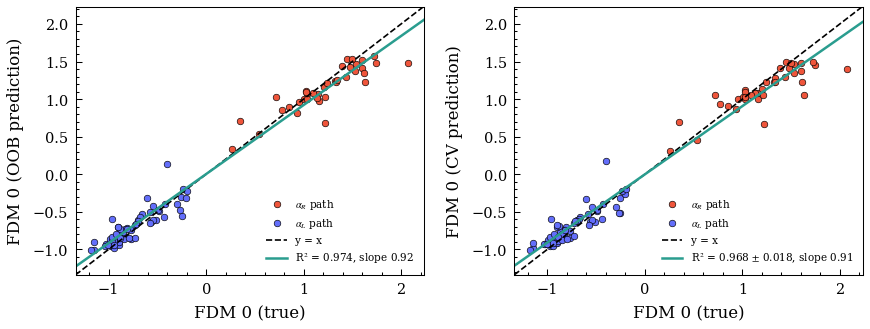

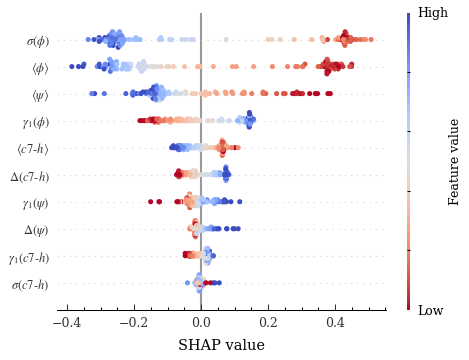

In [5]:
plot_parity(res, labels, D.LABEL_CONFIG); plt.tight_layout(); plt.show()
plot_beeswarm(res, max_display=10); plt.show()

## Setting: statistics on the denoised path

All four statistics on the denoised path instead of the mixed scheme above.

In [6]:
X2, _ = feature_matrix(desc, D.DESC_NAMES, stats_on="denoised")
res2 = fit_surrogate(X2, Z[:, 0], names)
print("all statistics on the denoised path:", res2.summary())
res2.table(5).round(3)

all statistics on the denoised path: 20 descriptors | out-of-bag R2 = 0.960 | 5-fold CV x 5: R2 = 0.953 +/- 0.027


,feature,shap_share,frac_folds_rank1
0,$\langle \phi \rangle$,0.359,1.0
1,$\langle \psi \rangle$,0.192,0.0
2,$\sigma(\phi)$,0.122,0.0
3,$\Delta(c7\text{-}h)$,0.087,0.0
4,$\langle c7\text{-}h \rangle$,0.062,0.0
